# Notebook 04: What is shear-wave splitting?

**Goal (about 2 hours, can be split over two sessions):** build the splitting measurement yourself on a synthetic signal where the answer is known. By the end you will have written a tiny version of what SWSPy does, and you will know exactly what "phi" and "dt" mean.

No library does the splitting here: just numpy. The physics reference is Crampin & Peacock (2008), *Wave Motion* 45, 675-722; the method is Silver & Chan (1991), *JGR* 96, 16429-16454.

In [1]:
# --- setup: make the repo importable and keep figures inline ---
import sys, warnings
from pathlib import Path
REPO = Path.cwd().parent if (Path.cwd() / "../rainier_sws").exists() else Path.cwd()
sys.path.insert(0, str(REPO))
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from rainier_sws import paths, data, measure, quality, stats
print("repo:", REPO)

repo: /Users/mhemmett/Seismology/rainier-sws-tutorials


## 1. The physical picture

Shallow rock is full of small cracks, and cracks tend to line up with the direction of maximum compressive stress (they close perpendicular to it). An S wave shaking the ground *parallel* to the cracks does not care about them and travels at the normal speed. An S wave shaking *across* the cracks has to compress the crack fluid and travels slightly slower.

A general S wave is a vector; decompose it into those two polarizations and the two parts travel at different speeds. By the time they reach the station the slow one lags the fast one by **dt**. The orientation of the fast one is **phi** (degrees clockwise from north; it is an axis so phi and phi + 180 are the same).

For an ECE student: the ground between earthquake and station is a two-input two-output linear system whose eigenmodes are "shake along phi" and "shake across phi", with impulse responses delta(t) and delta(t - dt). We want to identify phi and dt from the output alone.

## 2. Make a split wave

Start with a clean S pulse polarized in some direction (the *source polarization*), then apply the split: rotate into the fast/slow frame, delay the slow component, rotate back to north/east.

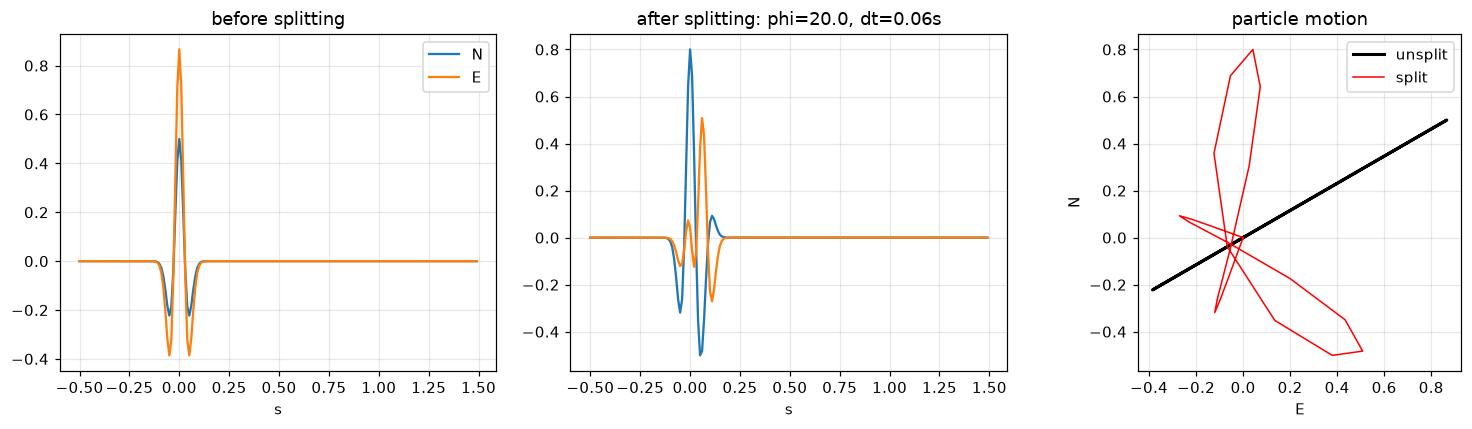

In [2]:
fs = 100.0
t = np.arange(-0.5, 1.5, 1 / fs)

def ricker(t, f0=8.0):
    a = (np.pi * f0 * t) ** 2
    return (1 - 2 * a) * np.exp(-a)

def split(n, e, phi, dt, fs=fs):
    """Apply splitting with fast axis phi (deg clockwise from N) and delay dt (s) to north/east traces."""
    # fast/slow frame: fast = component along phi, slow = perpendicular
    th = np.deg2rad(phi)
    fast = n * np.cos(th) + e * np.sin(th)
    slow = -n * np.sin(th) + e * np.cos(th)
    slow = np.roll(slow, int(round(dt * fs)))          # delay the slow wave
    n2 = fast * np.cos(th) - slow * np.sin(th)
    e2 = fast * np.sin(th) + slow * np.cos(th)
    return n2, e2

src_pol, PHI_TRUE, DT_TRUE = 60.0, 20.0, 0.06
pulse = ricker(t)
n0, e0 = pulse * np.cos(np.deg2rad(src_pol)), pulse * np.sin(np.deg2rad(src_pol))   # unsplit
n1, e1 = split(n0, e0, PHI_TRUE, DT_TRUE)                                             # split

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(t, n0, label="N"); axes[0].plot(t, e0, label="E"); axes[0].set_title("before splitting"); axes[0].legend()
axes[1].plot(t, n1, label="N"); axes[1].plot(t, e1, label="E"); axes[1].set_title(f"after splitting: phi={PHI_TRUE}, dt={DT_TRUE}s")
axes[2].plot(e0, n0, "k", lw=2, label="unsplit"); axes[2].plot(e1, n1, "r", lw=1, label="split")
axes[2].set_aspect("equal"); axes[2].set_xlabel("E"); axes[2].set_ylabel("N"); axes[2].set_title("particle motion"); axes[2].legend()
for ax in axes[:2]: ax.set_xlabel("s")
plt.tight_layout()

The right panel is the key diagnostic in all of shear-wave splitting. An unsplit S wave has **linear** particle motion (the ground moves back and forth along one line). After splitting, the two delayed components combine into an **ellipse**. The whole measurement is: find the (phi, dt) that turns the ellipse back into a line.

## 3. Undo the split: the grid search

For a trial (phi, dt): rotate into the trial fast/slow frame, advance the slow component by dt, and ask how linear the motion now is. Linearity is measured by the eigenvalues of the 2x2 covariance matrix of the two components: a line has one large eigenvalue and one that is (almost) zero. So we minimize the smaller eigenvalue lambda2 over a grid (Silver & Chan's "eigenvalue method"). SWSPy also uses the cross-correlation between the two components; we keep it simple.

In [3]:
def unsplit(n, e, phi, dt, fs=fs):
    th = np.deg2rad(phi)
    fast = n * np.cos(th) + e * np.sin(th)
    slow = -n * np.sin(th) + e * np.cos(th)
    slow = np.roll(slow, -int(round(dt * fs)))
    return fast, slow

def lambda2(n, e, phi, dt, win):
    f, s = unsplit(n, e, phi, dt)
    cov = np.cov(np.vstack([f[win], s[win]]))
    return np.linalg.eigvalsh(cov)[0]          # smaller eigenvalue

phis = np.arange(0, 180, 1.0)
dts = np.arange(0, 0.2, 0.01)
win = (t > -0.2) & (t < 0.6)                   # analysis window around the pulse
grid = np.array([[lambda2(n1, e1, p, d, win) for d in dts] for p in phis])
ip, idt = np.unravel_index(np.argmin(grid), grid.shape)
print(f"recovered phi = {phis[ip]:.0f} deg, dt = {dts[idt]:.2f} s   (truth: {PHI_TRUE}, {DT_TRUE})")

recovered phi = 20 deg, dt = 0.06 s   (truth: 20.0, 0.06)


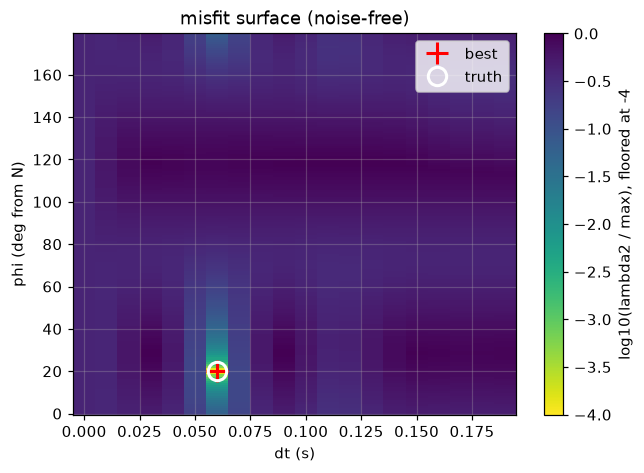

In [4]:
def show_grid(grid, phis, dts, title, truth=None):
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    # relative to the maximum, floored: a noise-free minimum is ~0, so dividing by the minimum would blow up
    rel = np.maximum(grid / grid.max(), 1e-4)
    im = ax.pcolormesh(dts, phis, np.log10(rel), shading="nearest", cmap="viridis_r")
    ax.set_xlabel("dt (s)"); ax.set_ylabel("phi (deg from N)"); ax.set_title(title)
    plt.colorbar(im, label="log10(lambda2 / max), floored at -4")
    ip, idt = np.unravel_index(np.argmin(grid), grid.shape)
    ax.plot(dts[idt], phis[ip], "r+", ms=14, mew=2, label="best")
    if truth: ax.plot(truth[1], truth[0], "wo", mfc="none", ms=12, mew=2, label="truth")
    ax.legend(loc="upper right")
show_grid(grid, phis, dts, "misfit surface (noise-free)", (PHI_TRUE, DT_TRUE))

Note the shape of the surface: a sharp minimum at the truth, a faint low band along the true dt at other phi, and higher-misfit bands about 0.03 s either side of the true dt. Swapping fast and slow (phi + 90) would need a negative dt, which the grid does not contain. Secondary minima along the dt axis are where **cycle skips** come from (exercise 2), and a surface with no single minimum is a **null** (section 6); notebook 07 screens for both.

## 4. Now add noise, and the error bars appear

Real seismograms are noisy. Add Gaussian noise at a chosen SNR and look at the misfit surface again. The minimum gets broader: the set of (phi, dt) that fit "almost as well" is the uncertainty. Silver & Chan turn this into a formal error with an F-test on the misfit; the broad idea is simply: *the width of the valley is the error bar.*

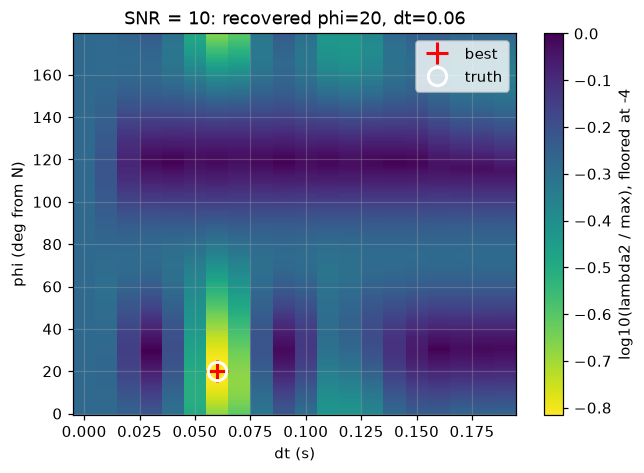

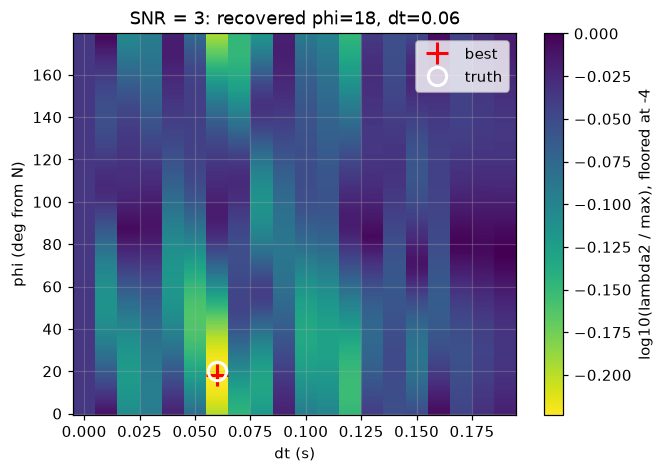

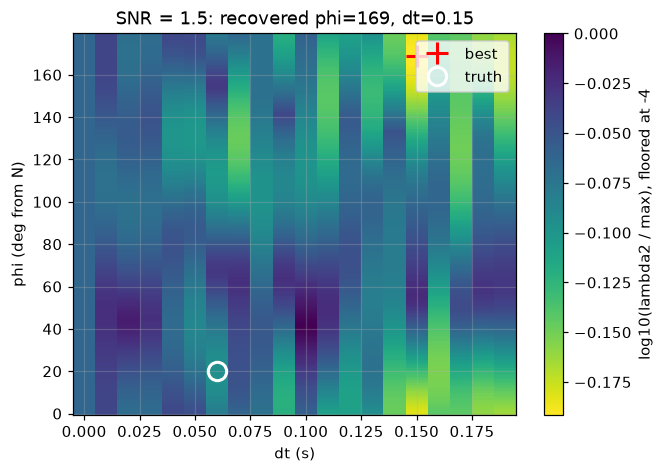

In [5]:
rng = np.random.default_rng(1)
def add_noise(n, e, snr):
    amp = np.max(np.abs(np.hypot(n, e))) / snr
    return n + rng.normal(0, amp, n.size), e + rng.normal(0, amp, e.size)

for snr in (10, 3, 1.5):
    nn, ee = add_noise(n1, e1, snr)
    g = np.array([[lambda2(nn, ee, p, d, win) for d in dts] for p in phis])
    ip, idt = np.unravel_index(np.argmin(g), g.shape)
    show_grid(g, phis, dts, f"SNR = {snr}: recovered phi={phis[ip]:.0f}, dt={dts[idt]:.2f}", (PHI_TRUE, DT_TRUE))

## 5. A first calibration experiment

Repeat the noisy recovery many times at each SNR and look at the spread of recovered phi and dt. This is the simplest possible answer to "how good is the measurement as a function of SNR?", and it is the template for the real calibration in notebook 07.

In [6]:
def recover(n, e):
    g = np.array([[lambda2(n, e, p, d, win) for d in dts] for p in phis])
    ip, idt = np.unravel_index(np.argmin(g), g.shape)
    return phis[ip], dts[idt]

snrs = [1.5, 2, 3, 5, 10, 20]
rows = []
for snr in snrs:
    for k in range(25):
        p, d = recover(*add_noise(n1, e1, snr))
        rows.append({"snr": snr, "phi": p, "dt": d})
res = pd.DataFrame(rows)
res["phi_err"] = stats.axial_diff(res.phi, PHI_TRUE)
res["dt_err"] = (res.dt - DT_TRUE).abs()
summary = res.groupby("snr").agg(phi_err_median=("phi_err", "median"), phi_err_p90=("phi_err", lambda x: np.percentile(x, 90)),
                                 dt_err_median=("dt_err", "median"), dt_err_p90=("dt_err", lambda x: np.percentile(x, 90)))
summary

,phi_err_median,phi_err_p90,dt_err_median,dt_err_p90
snr,,,,
1.5,39.0,66.4,0.05,0.106
2.0,35.0,49.6,0.03,0.100
3.0,26.0,51.4,0.01,0.126
5.0,9.0,29.6,0.00,0.050
10.0,3.0,8.2,0.00,0.000
20.0,2.0,4.0,0.00,0.000


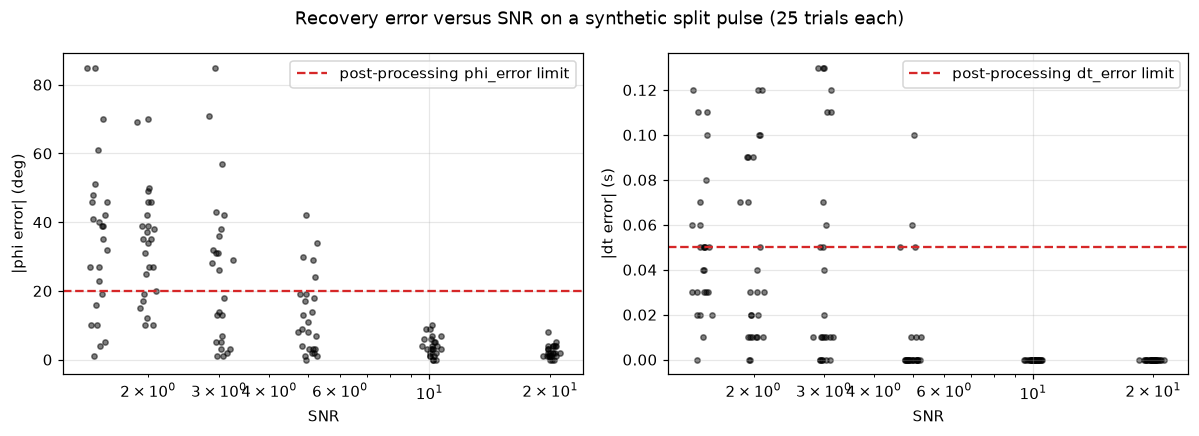

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, lab in zip(axes, ["phi_err", "dt_err"], ["|phi error| (deg)", "|dt error| (s)"]):
    ax.scatter(res.snr + rng.normal(0, 0.03, len(res)) * res.snr, res[col], s=12, alpha=0.5, c="k")
    ax.set_xscale("log"); ax.set_xlabel("SNR"); ax.set_ylabel(lab)
axes[0].axhline(20, color="tab:red", ls="--", label="post-processing phi_error limit"); axes[0].legend()
axes[1].axhline(0.05, color="tab:red", ls="--", label="post-processing dt_error limit"); axes[1].legend()
fig.suptitle("Recovery error versus SNR on a synthetic split pulse (25 trials each)")
plt.tight_layout()

At SNR 3 and below the median phi error is above 20 degrees (the post-processing limit); at SNR 5 the median is 9 degrees but one trial in ten is still about 30 degrees off; by SNR 10 the measurement is excellent (median 3 degrees). The research pipeline's SNR gate of 2.0 sits right at the edge; whether that is a good choice for *real* data (where noise is not white and the source pulse is not a clean Ricker) is a question you will test with real seismograms in notebook 07.

## 6. The null measurement

What if the source polarization happens to be *along* the fast axis (or exactly across it)? Then there is no slow component to delay, the wave arrives unsplit, and the misfit surface has no meaningful minimum: phi is undetermined and dt can be anything. These "nulls" are not failures of the method, they are real and informative, but a naive grid search still returns a number for them.

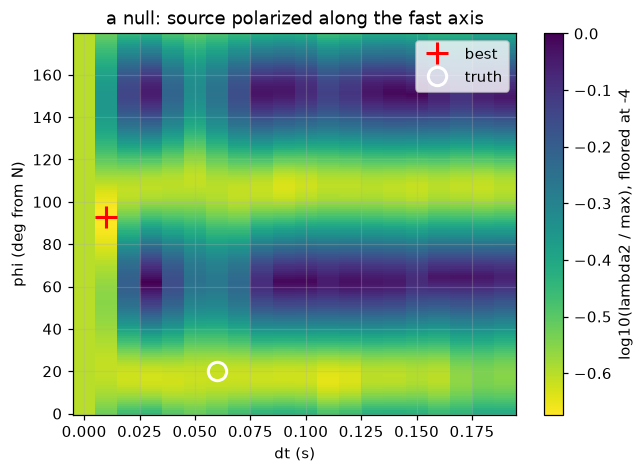

In [8]:
n_null, e_null = pulse * np.cos(np.deg2rad(PHI_TRUE)), pulse * np.sin(np.deg2rad(PHI_TRUE))  # source pol == phi
nn, ee = add_noise(*split(n_null, e_null, PHI_TRUE, DT_TRUE), 10)
g = np.array([[lambda2(nn, ee, p, d, win) for d in dts] for p in phis])
show_grid(g, phis, dts, "a null: source polarized along the fast axis", (PHI_TRUE, DT_TRUE))

The surface is a trough along a whole line rather than a point: dt is unconstrained (any dt gives the same misfit) and phi is only known to be either the source polarization or 90 degrees from it. In real data, nulls show up as phi near the back azimuth or perpendicular to it with a large dt error. Notebook 07 screens for them.

## 7. What it looks like in real data: a good split, a null and a cycle skip

Everything so far was synthetic. Here are three real measurements made with the same pipeline you will run in notebook 05 (SWSPy with the MFAST filter bank, many analysis windows, and DBSCAN clustering of the window results). They come from Michael's other project, station AXEC2 on the summit caldera of **Axial Seamount**, an ocean-bottom volcano, because that dataset has clean textbook examples of each case. The figures are from `axial-sws/scripts/figure_axec2_mfast_event_*_diagnostics.py`.

Every figure has the same panels:

- **A**: the three components, P pick (blue), S pick (red) and the analysis windows (grey).
- **Original / corrected particle motion**: the two horizontal components plotted against each other in the ray frame (Q against T), before and after undoing the best-fitting split.
- **phi-dt parameter space**: the misfit surface from section 3, coloured by the normalised eigenvalue ratio (low = good fit), with the best solution marked and the cycle-skip limit T_dom/2 as a dashed line. Here phi is measured from Q, the ray frame, not from north.
- **DBSCAN clustering**: the answer from each of the 49 analysis windows. Agreeing windows form one tight cluster.

Read the three side by side; the differences are what a quality filter has to catch.

### A good split

![A high-quality split at AXEC2](images/sws_example_good_split_axec2.png)

Event 298_74456 (21 April 2015): phi 14 degrees from Q, dt 0.030 s, Q_w 1.0, SNR 23, rectilinearity 0.999, incidence 15 degrees. This is what you want every measurement to look like:

- **Particle motion**: an open ellipse before correction (C) collapses to a nearly straight line after (D). That is the signature of splitting, exactly as in your synthetic of section 2.
- **Misfit surface** (B): one small, closed minimum, well to the left of T_dom/2, with the repeating minima at larger dt (the cycle-skip candidates) clearly worse.
- **Windows** (E, F, G): 41 of 49 windows land in one cluster, and phi and dt barely move from window to window.

*Caveat*: this figure was made in July 2026, before the axial-sws project corrected its own component orientations (October 2026). Use it for what a good split looks like, not for its phi value.

### A null

![A null measurement at AXEC2](images/sws_example_null_axec2.png)

Event 12_2753 (31 January 2015): the pipeline reports phi 20 degrees from Q and dt 0.050 s with tiny errors (3 degrees, 0.005 s), at SNR 18 and rectilinearity 0.99. It passes every post-processing cut **except** the quality factor: Q_w = -0.92.

- **Particle motion**: already nearly linear before correction (B), and the "correction" hardly changes it (C). There was little or no splitting to undo, the case of section 6.
- **Misfit surface** (D): no single closed minimum but a broad low (dark) region, flanked by bands along two directions 90 degrees apart, the source polarization and its perpendicular. The grid search still picks a point and its formal errors look small.
- **Windows** (E): the windows agree with each other perfectly, because they all see the same unsplit wave.

Q_w (Wüstefeld et al., 2010) compares the eigenvalue answer with an independent cross-correlation answer; near -1 means "these agree only in the way nulls agree". Without that cut, this precise-looking number would go straight into a rose diagram. A null is information (the source polarization is close to the fast axis or perpendicular to it), not a fast direction.

### A cycle skip

![A cycle-skipped measurement at AXEC2](images/sws_example_cycle_skip_axec2.png)

Event 16_3842 (31 January 2015): phi -30 degrees from Q, **dt 0.160 s**, Q_w 0.97, SNR 12, rectilinearity 0.99, errors at the grid floor (2 degrees, 0.005 s). The dominant period is 0.160 s, so dt is a whole period: twice the T_dom/2 limit.

- **Misfit surface** (D): there are good minima on both sides of the dashed T_dom/2 line, repeating along dt every half period or so, the comb you made in exercise 2. The best solution sits one full cycle out: the grid search matched each wiggle of the slow wave with the *next* wiggle of the fast one.
- **Windows** (E): two clusters, about 15 windows near 0.10 s and about 30 near 0.16 s, at the same phi. The pipeline picks the bigger one.
- **Particle motion** (B, C): linearised after "correction", because shifting by a whole period also lines the wiggles up.

Every quality number says this is excellent. Only the rule **dt <= T_dom / 2** removes it, which is why that cut is in the post-processing filter (`quality.PostFilter.dt_period_fraction`) and why the dominant period is recorded for every measurement (notebook 03).

## 8. Exercises

1. Change the source polarization to 30 degrees from the fast axis. Is the ellipse fatter or thinner? Does the recovery at SNR 2 get better or worse?
2. Make the pulse higher frequency (`f0 = 15`) with the same dt. What happens to the misfit surface along the dt axis? (This is cycle skipping.)
3. Reduce the window `win` to just the first half of the pulse. Does the minimum move? Window choice is another knob the real pipeline sweeps over (`n_win = 7`).
4. Write `recover` as a function that also returns the *width* of the valley (for example the range of phi for which lambda2 is within 10 percent of its minimum). Plot that width against the actual error. Are they related? That relationship is what a formal error bar tries to capture.

Next: `04b_timing_and_clock_errors.ipynb` (same week): before trusting a window placed from a pick, check the clock. Then `05_single_event_with_swspy.ipynb`, the real thing.

## 9. Example solutions

One way to do each exercise. Try them yourself first. Everything reuses the functions above (`ricker`, `split`, `lambda2`, `add_noise`, `show_grid`), and nothing above is changed. The noise is random, so a fresh generator is seeded here to make the numbers repeatable.

### Exercise 1: source polarization 30 degrees from the fast axis

The lesson's source polarization (60 degrees) is 40 degrees from the fast axis (20). Move it to 50, which is 30 degrees from the fast axis, and compare. Two numbers summarise "how fat is the ellipse": the ratio of the small to the large eigenvalue of the split N/E covariance (0 for a line, 1 for a circle).

,phi_err_median,dt_err_median,fraction_phi_within_20
case,,,
30 deg from fast,44.5,0.05,0.29
40 deg from fast (lesson),35.0,0.04,0.32


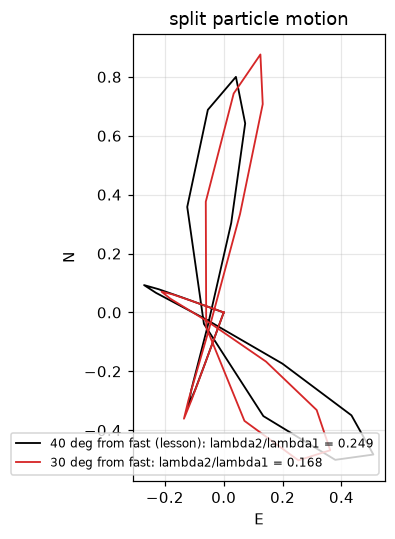

In [9]:
rng = np.random.default_rng(42)

def make_split(src_pol, f0=8.0, phi=PHI_TRUE, dt=DT_TRUE):
    p = ricker(t, f0)
    return split(p * np.cos(np.deg2rad(src_pol)), p * np.sin(np.deg2rad(src_pol)), phi, dt)

def ellipticity(n, e):
    lam = np.linalg.eigvalsh(np.cov(np.vstack([n[win], e[win]])))
    return lam[0] / lam[1]

cases = {"40 deg from fast (lesson)": make_split(60.0), "30 deg from fast": make_split(50.0)}
fig, ax = plt.subplots(figsize=(5, 5))
for (label, (n_, e_)), colour in zip(cases.items(), ["k", "tab:red"]):
    ax.plot(e_, n_, color=colour, lw=1.2, label=f"{label}: lambda2/lambda1 = {ellipticity(n_, e_):.3f}")
ax.set_aspect("equal"); ax.set_xlabel("E"); ax.set_ylabel("N"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("split particle motion")
plt.tight_layout()

rows = []
for label, (n_, e_) in cases.items():
    for k in range(100):
        p_, d_ = recover(*add_noise(n_, e_, 2))
        rows.append({"case": label, "phi_err": stats.axial_diff(p_, PHI_TRUE), "dt_err": abs(d_ - DT_TRUE)})
pd.DataFrame(rows).groupby("case").agg(phi_err_median=("phi_err", "median"), dt_err_median=("dt_err", "median"),
                                       fraction_phi_within_20=("phi_err", lambda x: (x <= 20).mean()))

**Thinner, and worse.** At 30 degrees from the fast axis the split ellipse is thinner (eigenvalue ratio 0.17 against 0.25 at 40 degrees). The fast and slow parts have amplitudes cos and sin of the angle between source polarization and fast axis, so the ellipse is fattest at 45 degrees and collapses to a line at 0 or 90, the null of section 6. A thinner ellipse means less signal for the grid search to undo, and at SNR 2 the median phi error rises from 35 to 44.5 degrees (100 trials each). The fraction of trials within 20 degrees barely changes (0.29 against 0.32), a difference smaller than the trial-to-trial scatter at this sample size.

At the real stations the source polarization is set by the earthquake's focal mechanism and the ray, not chosen, so every event sits somewhere on this curve, and events near 0 or 90 degrees from the fast axis are near-nulls.

### Exercise 2: a higher-frequency pulse

Same split (phi 20, dt 0.06 s), but `f0 = 15` instead of 8. The second panel takes a slice through each misfit surface at the true phi, so the shape along the dt axis is easy to see.

f0 = 15 Hz, SNR 10: recovered dt values (count): {0.06: 50}


f0 = 15 Hz, SNR 3: recovered dt values (count): {0.01: 1, 0.02: 2, 0.03: 4, 0.04: 1, 0.05: 1, 0.06: 11, 0.07: 3, 0.08: 4, 0.09: 5, 0.1: 1, 0.11: 2, 0.12: 2, 0.14: 3, 0.15: 3, 0.16: 1, 0.17: 1, 0.19: 5}


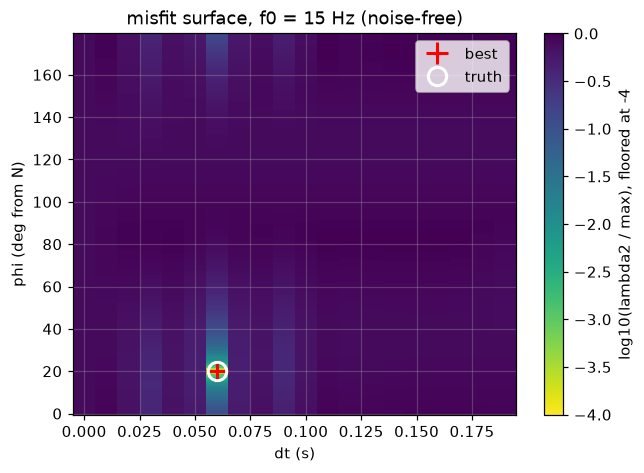

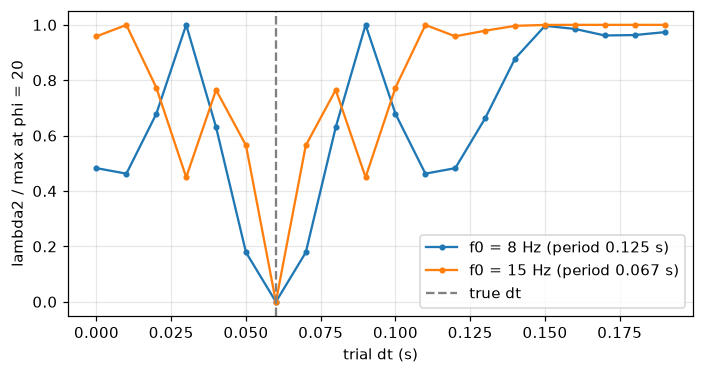

In [10]:
n15, e15 = make_split(60.0, f0=15.0)
g15 = np.array([[lambda2(n15, e15, p, d, win) for d in dts] for p in phis])
show_grid(g15, phis, dts, "misfit surface, f0 = 15 Hz (noise-free)", (PHI_TRUE, DT_TRUE))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
for f0, g_ in [(8.0, grid), (15.0, g15)]:
    slice_ = g_[list(phis).index(PHI_TRUE)]
    ax.plot(dts, slice_ / slice_.max(), "o-", ms=3, label=f"f0 = {f0:g} Hz (period {1 / f0:.3f} s)")
ax.axvline(DT_TRUE, color="0.5", ls="--", label="true dt")
ax.set_xlabel("trial dt (s)"); ax.set_ylabel("lambda2 / max at phi = 20"); ax.legend()
plt.tight_layout()

for snr in (10, 3):
    found = [recover(*add_noise(n15, e15, snr))[1] for _ in range(50)]
    print(f"f0 = 15 Hz, SNR {snr}: recovered dt values (count): {pd.Series(found).round(2).value_counts().sort_index().to_dict()}")

At 15 Hz the period (0.067 s) is barely longer than the delay (0.06 s). Without noise the grid still finds the truth exactly, but the slice at phi = 20 shows the change: the side minima, at about 0.03 and 0.09 s, sit only 0.03 s either side of the truth, with misfit about 0.45 of the maximum, against 0.01 and 0.11 s for the 8 Hz pulse. Higher frequency packs the wiggles of the misfit closer together along dt.

Add noise and the grid starts jumping to them. At SNR 10 all 50 trials still return 0.06 s, but at SNR 3 only 11 of 50 do, and the rest scatter over the whole dt range with clumps at 0.03, 0.08 to 0.09 and 0.19 s. That is **cycle skipping**: the slow wave is matched to the wrong wiggle of the fast one. It is why the pipeline rejects a dt longer than half the dominant period (`PostFilter.dt_period_fraction`); here dt is 0.9 of the period, so even a correct-looking answer would be flagged.

### Exercise 3: a window over only the first half of the pulse

The pulse is centred on t = 0, so "the first half" is the window from -0.2 s to 0 s. `recover` uses the global `win`, so the grid is written out here with the window as an argument.

noise-free, full window : phi = 20, dt = 0.06
noise-free, first half  : phi = 20, dt = 0.06


,phi_err_median,phi_err_p90,dt_err_median
window,,,
first half,52.0,84.3,0.035
full window,10.5,34.1,0.010


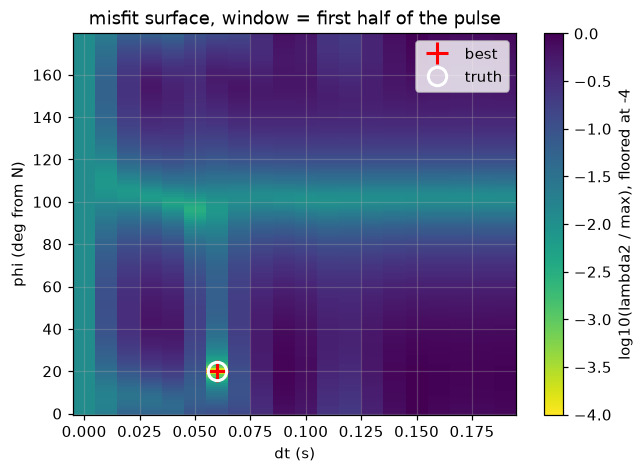

In [11]:
def recover_win(n, e, w):
    g_ = np.array([[lambda2(n, e, p, d, w) for d in dts] for p in phis])
    ip_, idt_ = np.unravel_index(np.argmin(g_), g_.shape)
    return phis[ip_], dts[idt_], g_

win_half = (t > -0.2) & (t < 0.0)
p_half, d_half, g_half = recover_win(n1, e1, win_half)
print(f"noise-free, full window : phi = {recover(n1, e1)[0]:.0f}, dt = {recover(n1, e1)[1]:.2f}")
print(f"noise-free, first half  : phi = {p_half:.0f}, dt = {d_half:.2f}")
show_grid(g_half, phis, dts, "misfit surface, window = first half of the pulse", (PHI_TRUE, DT_TRUE))

rows = []
for label, w in [("full window", win), ("first half", win_half)]:
    for k in range(50):
        p_, d_, _ = recover_win(*add_noise(n1, e1, 5), w)
        rows.append({"window": label, "phi_err": stats.axial_diff(p_, PHI_TRUE), "dt_err": abs(d_ - DT_TRUE)})
pd.DataFrame(rows).groupby("window").agg(phi_err_median=("phi_err", "median"), phi_err_p90=("phi_err", lambda x: np.percentile(x, 90)),
                                         dt_err_median=("dt_err", "median"))

Without noise the minimum does not move (phi 20, dt 0.06 either way), but the surface changes: new low-misfit bands appear, along phi of about 100 to 110 (90 degrees from the truth) and along small dt, competing with the true minimum. With noise (SNR 5, 50 trials) that matters a lot: the median phi error goes from 10.5 degrees with the full window to 52 with the half window, the 90th percentile from 34 to 84, and the median dt error from 0.01 to 0.035 s.

The reason is in the data, not the method: the half window ends at t = 0, but the slow wave is delayed by 0.06 s, so most of it lies *outside* the window. The window has to contain both the fast and the slow arrival. That is why SWSPy does not trust one window but tries many start and end times (`n_win`) and clusters the answers.

### Exercise 4: the width of the valley as an error bar

For each phi take the best lambda2 over all dt; the valley width is how many degrees of phi come within 10 percent of the overall minimum. Run many noisy trials at several SNRs and compare the width with the actual error.

     width_median  phi_err_median
snr                              
2            80.5            37.5
3            80.5            15.0
5            44.0             8.5
10           25.0             5.0

Spearman rank correlation, width vs error, all trials: 0.55
fraction of trials with error larger than half the width: 0.20


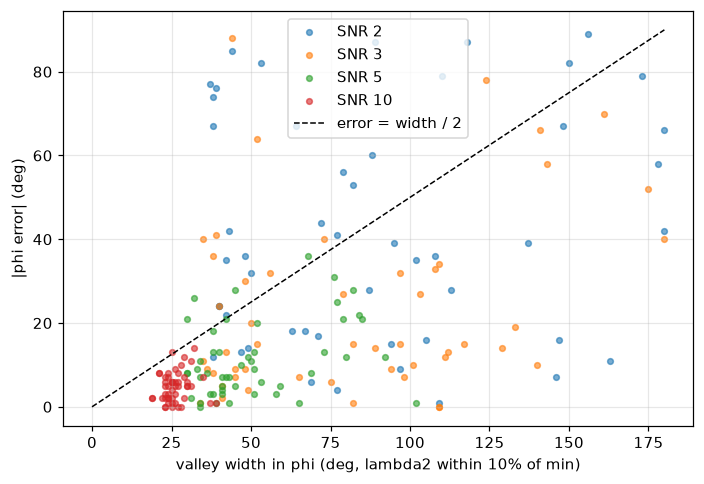

In [12]:
def recover_with_width(n, e, tol=0.10):
    g_ = np.array([[lambda2(n, e, p, d, win) for d in dts] for p in phis])
    ip_, idt_ = np.unravel_index(np.argmin(g_), g_.shape)
    best_per_phi = g_.min(axis=1)
    width = np.sum(best_per_phi <= g_.min() * (1 + tol)) * (phis[1] - phis[0])   # degrees of phi inside the valley
    return phis[ip_], dts[idt_], width

rows = []
for snr in (2, 3, 5, 10):
    for k in range(50):
        p_, d_, w_ = recover_with_width(*add_noise(n1, e1, snr))
        rows.append({"snr": snr, "phi_err": stats.axial_diff(p_, PHI_TRUE), "width": w_})
ww = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for snr, g_ in ww.groupby("snr"):
    ax.scatter(g_.width, g_.phi_err, s=14, alpha=0.6, label=f"SNR {snr}")
lim = max(ww.width.max(), ww.phi_err.max())
ax.plot([0, lim], [0, lim / 2], "k--", lw=1, label="error = width / 2")
ax.set_xlabel("valley width in phi (deg, lambda2 within 10% of min)"); ax.set_ylabel("|phi error| (deg)"); ax.legend()
plt.tight_layout()

print(ww.groupby("snr").agg(width_median=("width", "median"), phi_err_median=("phi_err", "median")).to_string())
print(f"\nSpearman rank correlation, width vs error, all trials: {ww.width.corr(ww.phi_err, method='spearman'):.2f}")
print(f"fraction of trials with error larger than half the width: {(ww.phi_err > ww.width / 2).mean():.2f}")

**Related, but not a guarantee.** On average a wider valley goes with a larger error: the median width shrinks from about 80 degrees at SNR 2 and 3 to 44 at SNR 5 and 25 at SNR 10, while the median error falls from 37.5 to 5 degrees, and the rank correlation over all 200 trials is 0.55. Most points sit below the error = width / 2 line, so half the width works as a rough error bar.

But one trial in five (0.20) has an error larger than half its width, and the worst of them are at SNR 2 with *narrow* valleys (widths of 35 to 55 degrees) and errors of 65 to 90 degrees: the noise created a sharp minimum in the wrong place. A narrow valley says the minimum is well defined, not that it is the right one. That is why a formal error bar (Silver and Chan's F-test does this more carefully than a 10 percent cut) is not enough on its own, and why the pipeline also checks that two different methods agree (Q_w) and that many windows give the same answer.